In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/mobeenfatimah/student-exam-performance-and-success-dataset/student_exam_performance.csv


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
import os

os.listdir("/kaggle/input")

['datasets']

In [4]:
import glob
import pandas as pd

csv_files = glob.glob("/kaggle/input/**/*.csv", recursive=True)

print(csv_files)

['/kaggle/input/datasets/mobeenfatimah/student-exam-performance-and-success-dataset/student_exam_performance.csv']


In [5]:
import glob

csv_files = glob.glob("/kaggle/input/**/*.csv", recursive=True)

print(csv_files)

['/kaggle/input/datasets/mobeenfatimah/student-exam-performance-and-success-dataset/student_exam_performance.csv']


In [6]:
df = pd.read_csv(csv_files[0])
df.shape

(100000, 44)

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 44 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   student_id                  100000 non-null  object 
 1   age                         100000 non-null  int64  
 2   gender                      100000 non-null  object 
 3   education_level             100000 non-null  object 
 4   school_type                 100000 non-null  object 
 5   family_income               100000 non-null  object 
 6   parent_education            93474 non-null   object 
 7   urban_rural                 100000 non-null  object 
 8   previous_exam_score         100000 non-null  float64
 9   previous_gpa                92207 non-null   float64
 10  attendance_percentage       90137 non-null   float64
 11  assignment_completion_rate  100000 non-null  float64
 12  class_participation         100000 non-null  object 
 13  study_hours_per

In [8]:
df.isnull().sum()

student_id                       0
age                              0
gender                           0
education_level                  0
school_type                      0
family_income                    0
parent_education              6526
urban_rural                      0
previous_exam_score              0
previous_gpa                  7793
attendance_percentage         9863
assignment_completion_rate       0
class_participation              0
study_hours_per_day              0
self_study_hours                 0
private_tuition                  0
online_learning_hours            0
study_consistency                0
study_environment                0
study_method                     0
revision_frequency               0
practice_tests_completed         0
notes_quality                 8407
sleep_hours                      0
sleep_quality                 6994
daily_screen_time                0
physical_activity_hours          0
break_frequency                  0
stress_level        

In [9]:
df.duplicated().sum()

np.int64(0)

In [10]:
df['previous_gpa'].value_counts()

previous_gpa
2.78    816
2.83    813
2.73    795
2.80    793
2.69    789
       ... 
1.08      1
1.09      1
1.07      1
1.11      1
1.06      1
Name: count, Length: 296, dtype: int64

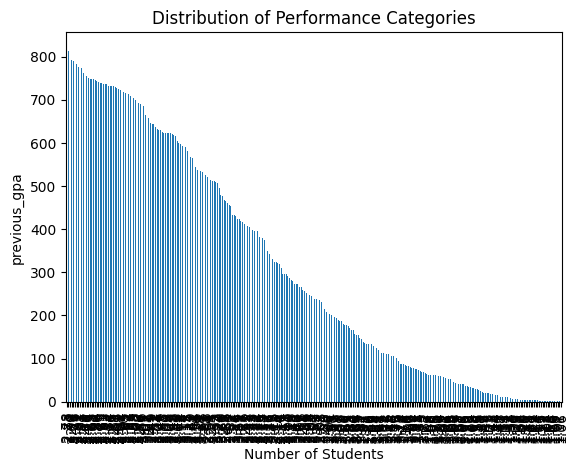

In [11]:
import matplotlib.pyplot as plt

df['previous_gpa'].value_counts().plot(kind='bar')
plt.ylabel('previous_gpa')
plt.xlabel('Number of Students')
plt.title('Distribution of Performance Categories')
plt.show()

In [12]:
df.columns

Index(['student_id', 'age', 'gender', 'education_level', 'school_type',
       'family_income', 'parent_education', 'urban_rural',
       'previous_exam_score', 'previous_gpa', 'attendance_percentage',
       'assignment_completion_rate', 'class_participation',
       'study_hours_per_day', 'self_study_hours', 'private_tuition',
       'online_learning_hours', 'study_consistency', 'study_environment',
       'study_method', 'revision_frequency', 'practice_tests_completed',
       'notes_quality', 'sleep_hours', 'sleep_quality', 'daily_screen_time',
       'physical_activity_hours', 'break_frequency', 'stress_level',
       'motivation_level', 'internet_access', 'device_availability',
       'educational_app_usage', 'online_course_hours', 'exam_difficulty',
       'exam_preparation_days', 'questions_attempted', 'questions_correct',
       'time_management_score', 'exam_anxiety_level', 'exam_score',
       'performance_grade', 'pass_status', 'performance_level'],
      dtype='object')

In [13]:
df.describe()

,age,previous_exam_score,previous_gpa,attendance_percentage,assignment_completion_rate,study_hours_per_day,self_study_hours,private_tuition,online_learning_hours,practice_tests_completed,...,physical_activity_hours,stress_level,internet_access,online_course_hours,exam_preparation_days,questions_attempted,questions_correct,time_management_score,exam_anxiety_level,exam_score
count,100000.000000,100000.000000,92207.000000,90137.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,...,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,90387.000000,100000.000000,100000.000000
mean,17.005740,69.531033,2.780892,84.616882,69.724405,2.995725,2.094970,0.299800,2.004763,5.509170,...,2.487579,9.375640,0.918760,2.999453,15.501440,92.492150,57.298240,78.398551,8.927373,61.950072
std,1.999562,11.379108,0.478218,7.922485,12.127179,1.719466,1.266066,0.458173,2.005719,2.501131,...,2.413386,1.081613,0.273205,2.983732,8.644356,4.609376,15.028787,14.105155,1.354875,15.863644
min,14.000000,30.000000,1.000000,46.340000,20.000000,0.500000,0.250000,0.000000,0.000000,0.000000,...,0.000000,5.000000,0.000000,0.000000,1.000000,85.000000,0.000000,17.030000,1.000000,0.000000
25%,15.000000,61.820000,2.460000,79.210000,61.480000,1.720000,1.170000,0.000000,0.580000,4.000000,...,0.720000,9.000000,1.000000,0.860000,8.000000,88.000000,47.000000,68.790000,8.220000,51.240000
50%,17.000000,69.530000,2.780000,84.750000,69.570000,2.670000,1.840000,0.000000,1.380000,5.000000,...,1.730000,10.000000,1.000000,2.080000,16.000000,92.000000,57.000000,79.000000,9.490000,61.960000
75%,19.000000,77.232500,3.110000,90.170000,77.920000,3.910000,2.730000,1.000000,2.770000,7.000000,...,3.480000,10.000000,1.000000,4.150000,23.000000,96.000000,67.000000,89.210000,10.000000,72.730000
max,20.000000,100.000000,4.000000,100.000000,100.000000,12.000000,10.000000,1.000000,15.000000,20.000000,...,12.000000,10.000000,1.000000,20.000000,30.000000,100.000000,100.000000,100.000000,10.000000,100.000000


In [14]:
df['pass_status'].value_counts()

pass_status
Pass    77389
Fail    22611
Name: count, dtype: int64

In [15]:
df['pass_status'].value_counts(normalize=True) * 100


pass_status
Pass    77.389
Fail    22.611
Name: proportion, dtype: float64

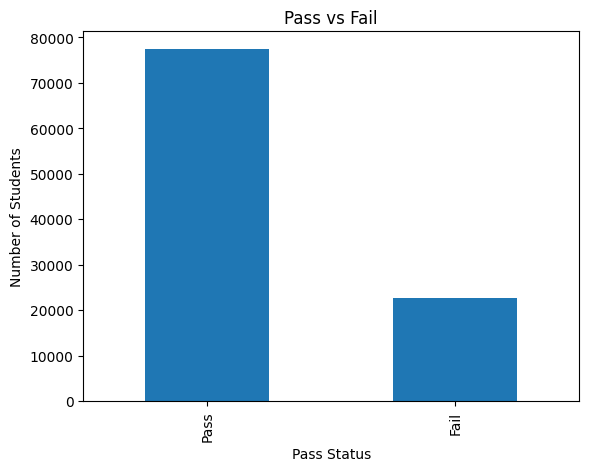

In [16]:
df['pass_status'].value_counts().plot(kind='bar')

plt.xlabel('Pass Status')
plt.ylabel('Number of Students')
plt.title('Pass vs Fail')
plt.show()

In [17]:
y = df['pass_status']

In [18]:
X = df.drop(columns=['pass_status', 'exam_score', 
                     'performance_grade', 'performance_level'])

In [19]:
df.groupby('pass_status')['previous_gpa'].mean()

pass_status
Fail    2.480577
Pass    2.868783
Name: previous_gpa, dtype: float64

In [20]:

df.groupby('pass_status')['attendance_percentage'].mean()


pass_status
Fail    82.833591
Pass    85.138114
Name: attendance_percentage, dtype: float64

In [21]:
df.groupby('pass_status')['study_hours_per_day'].mean()

pass_status
Fail    2.283495
Pass    3.203819
Name: study_hours_per_day, dtype: float64

In [22]:
df.groupby('pass_status')['exam_anxiety_level'].mean()

pass_status
Fail    9.146810
Pass    8.863259
Name: exam_anxiety_level, dtype: float64

In [23]:
df.groupby('pass_status')['stress_level'].mean()

pass_status
Fail    9.591969
Pass    9.312435
Name: stress_level, dtype: float64

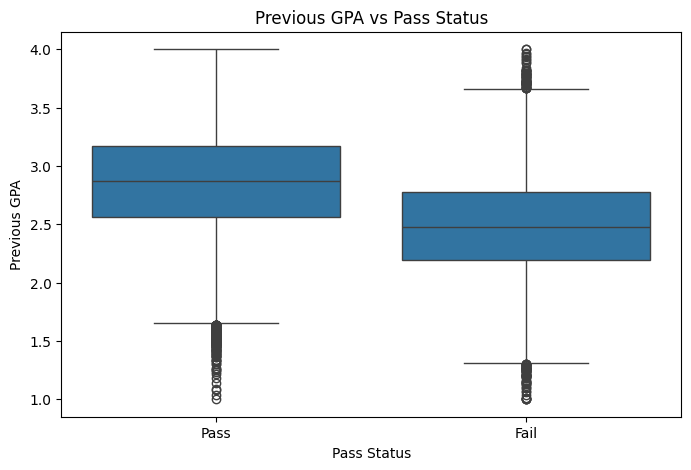

In [24]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x='pass_status', y='previous_gpa')

plt.xlabel('Pass Status')
plt.ylabel('Previous GPA')
plt.title('Previous GPA vs Pass Status')

plt.show()

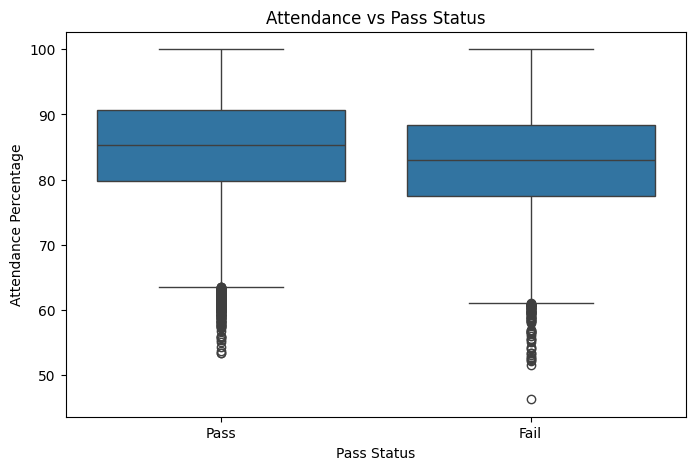

In [25]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x='pass_status', y='attendance_percentage')

plt.xlabel('Pass Status')
plt.ylabel('Attendance Percentage')
plt.title('Attendance vs Pass Status')

plt.show()

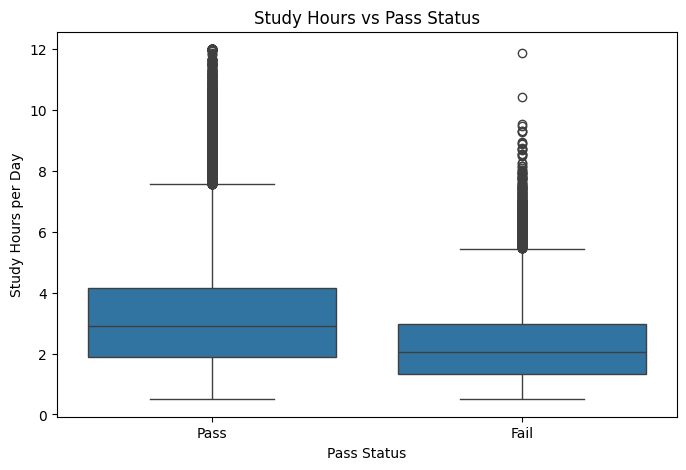

In [26]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x='pass_status', y='study_hours_per_day')

plt.xlabel('Pass Status')
plt.ylabel('Study Hours per Day')
plt.title('Study Hours vs Pass Status')

plt.show()

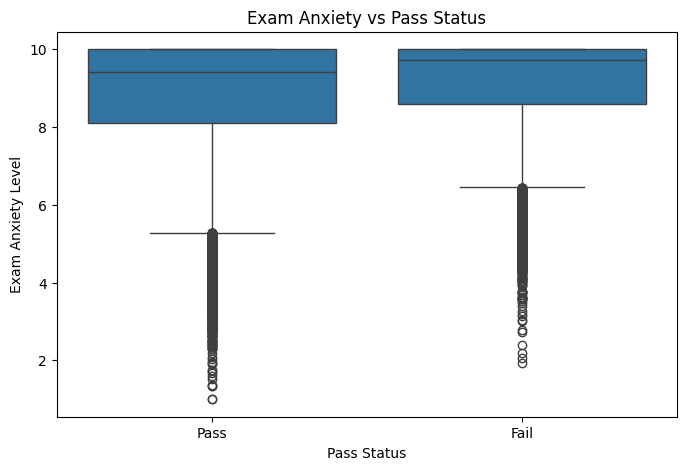

In [27]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x='pass_status', y='exam_anxiety_level')

plt.xlabel('Pass Status')
plt.ylabel('Exam Anxiety Level')
plt.title('Exam Anxiety vs Pass Status')

plt.show()

In [28]:
df.isnull().sum()

student_id                       0
age                              0
gender                           0
education_level                  0
school_type                      0
family_income                    0
parent_education              6526
urban_rural                      0
previous_exam_score              0
previous_gpa                  7793
attendance_percentage         9863
assignment_completion_rate       0
class_participation              0
study_hours_per_day              0
self_study_hours                 0
private_tuition                  0
online_learning_hours            0
study_consistency                0
study_environment                0
study_method                     0
revision_frequency               0
practice_tests_completed         0
notes_quality                 8407
sleep_hours                      0
sleep_quality                 6994
daily_screen_time                0
physical_activity_hours          0
break_frequency                  0
stress_level        

In [29]:
y = df['pass_status']

In [30]:
X = df.drop(columns=[
    'pass_status',
    'exam_score',
    'performance_grade',
    'performance_level',
    'student_id'
])

In [31]:
print(X.shape)
print(y.shape)

(100000, 39)
(100000,)


In [32]:
numeric_cols = X.select_dtypes(include=['int64', 'float64']).columns
categorical_cols = X.select_dtypes(include=['object']).columns

print("Numerical columns:")
print(numeric_cols)

print("\nCategorical columns:")
print(categorical_cols)

Numerical columns:
Index(['age', 'previous_exam_score', 'previous_gpa', 'attendance_percentage',
       'assignment_completion_rate', 'study_hours_per_day', 'self_study_hours',
       'private_tuition', 'online_learning_hours', 'practice_tests_completed',
       'sleep_hours', 'daily_screen_time', 'physical_activity_hours',
       'stress_level', 'internet_access', 'online_course_hours',
       'exam_preparation_days', 'questions_attempted', 'questions_correct',
       'time_management_score', 'exam_anxiety_level'],
      dtype='object')

Categorical columns:
Index(['gender', 'education_level', 'school_type', 'family_income',
       'parent_education', 'urban_rural', 'class_participation',
       'study_consistency', 'study_environment', 'study_method',
       'revision_frequency', 'notes_quality', 'sleep_quality',
       'break_frequency', 'motivation_level', 'device_availability',
       'educational_app_usage', 'exam_difficulty'],
      dtype='object')


In [33]:
for col in numeric_cols:
    X[col] = X[col].fillna(X[col].median())

for col in categorical_cols:
    X[col] = X[col].fillna(X[col].mode()[0])

In [34]:
print(X.isnull().sum().sum())

0


In [35]:
X = pd.get_dummies(
    X,
    columns=categorical_cols,
    drop_first=True
)

print(X.shape)

(100000, 62)


In [36]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print(X_scaled.shape)

(100000, 62)


In [37]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_scaled,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training targets:", y_train.shape)
print("Testing targets:", y_test.shape)

Training features: (80000, 62)
Testing features: (20000, 62)
Training targets: (80000,)
Testing targets: (20000,)


In [38]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=1000)

model.fit(X_train, y_train)

print("Model training completed!")

Model training completed!


In [39]:
y_pred = model.predict(X_test)

print("First 10 actual results:")
print(y_test.iloc[:10].values)

print("\nFirst 10 predicted results:")
print(y_pred[:10])

First 10 actual results:
['Pass' 'Fail' 'Pass' 'Fail' 'Pass' 'Pass' 'Fail' 'Pass' 'Pass' 'Pass']

First 10 predicted results:
['Pass' 'Fail' 'Pass' 'Fail' 'Pass' 'Pass' 'Fail' 'Pass' 'Pass' 'Pass']


In [40]:
from sklearn.metrics import accuracy_score, classification_report

accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", round(accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Model Accuracy: 97.68 %

Classification Report:
              precision    recall  f1-score   support

        Fail       0.95      0.95      0.95      4522
        Pass       0.99      0.98      0.98     15478

    accuracy                           0.98     20000
   macro avg       0.97      0.97      0.97     20000
weighted avg       0.98      0.98      0.98     20000



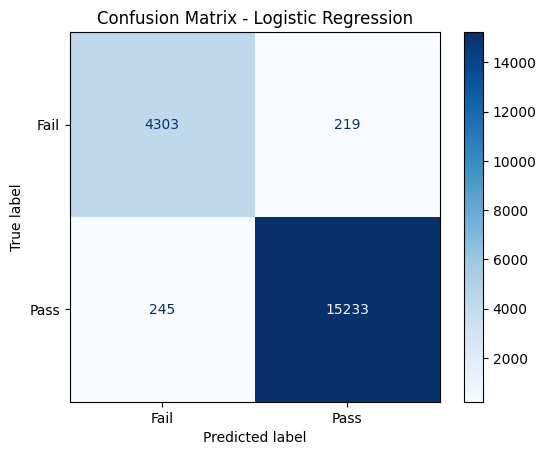

In [41]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=['Fail', 'Pass']
)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Fail', 'Pass']
)

display.plot(cmap='Blues')
plt.title('Confusion Matrix - Logistic Regression')
plt.show()

In [42]:
print(
    df.groupby('pass_status')['exam_score']
      .agg(['min', 'max', 'mean', 'median'])
)

              min     max       mean  median
pass_status                                 
Fail          0.0   49.99  40.765101   42.74
Pass         50.0  100.00  68.139755   66.56


In [43]:
print(
    df.groupby('pass_status')[
        ['questions_correct', 'questions_attempted']
    ].mean()
)

             questions_correct  questions_attempted
pass_status                                        
Fail                 37.700809            92.457565
Pass                 63.024086            92.502255


In [44]:

y = df['pass_status']

X = df.drop(columns=[
    'pass_status',
    'exam_score',
    'performance_grade',
    'performance_level',
    'student_id',
    'questions_correct'
])

print("Features:", X.shape)
print("Target:", y.shape)

Features: (100000, 38)
Target: (100000,)


In [45]:

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)


Training features: (80000, 38)
Testing features: (20000, 38)
Training target: (80000,)
Testing target: (20000,)


In [46]:

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

categorical_columns = X_train.select_dtypes(
    include=['object', 'category', 'bool']
).columns

numerical_columns = X_train.select_dtypes(
    include=['number']
).columns

preprocessor = ColumnTransformer(
    transformers=[
        ('cat', Pipeline([
            ('imputer', SimpleImputer(strategy='most_frequent')),
            ('encoder', OneHotEncoder(handle_unknown='ignore'))
        ]), categorical_columns),

        ('num', SimpleImputer(strategy='median'), numerical_columns)
    ]
)

model = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(max_iter=1000))
])

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Accuracy: 0.8475
              precision    recall  f1-score   support

        Fail       0.71      0.55      0.62      4522
        Pass       0.88      0.94      0.90     15478

    accuracy                           0.85     20000
   macro avg       0.79      0.74      0.76     20000
weighted avg       0.84      0.85      0.84     20000



In [47]:

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

categorical_columns = X_train.select_dtypes(
    include=['object', 'category', 'bool']
).columns

numerical_columns = X_train.select_dtypes(
    include=['number']
).columns

preprocessor = ColumnTransformer([
    ('cat', Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('encoder', OneHotEncoder(handle_unknown='ignore'))
    ]), categorical_columns),

    ('num', Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
    ]), numerical_columns)
])

model = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(
        max_iter=3000,
        class_weight='balanced'
    ))
])

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))


Accuracy: 0.7975
              precision    recall  f1-score   support

        Fail       0.53      0.82      0.65      4522
        Pass       0.94      0.79      0.86     15478

    accuracy                           0.80     20000
   macro avg       0.74      0.81      0.75     20000
weighted avg       0.85      0.80      0.81     20000



In [48]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report


rf_model = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(
        n_estimators=200,
        class_weight='balanced',
        random_state=42,
        n_jobs=-1
    ))
])

rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)


print("Random Forest Accuracy:",
      accuracy_score(y_test, rf_pred))

print(classification_report(y_test, rf_pred))


Random Forest Accuracy: 0.8366
              precision    recall  f1-score   support

        Fail       0.78      0.39      0.52      4522
        Pass       0.84      0.97      0.90     15478

    accuracy                           0.84     20000
   macro avg       0.81      0.68      0.71     20000
weighted avg       0.83      0.84      0.82     20000



In [49]:

feature_names = rf_model.named_steps[
    'preprocessor'
].get_feature_names_out()

importances = rf_model.named_steps[
    'classifier'
].feature_importances_

import pandas as pd

importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
}).sort_values('Importance', ascending=False)

print(importance_df.head(15))


                            Feature  Importance
60         num__previous_exam_score    0.126268
61                num__previous_gpa    0.085090
75       num__exam_preparation_days    0.061054
64         num__study_hours_per_day    0.059909
65            num__self_study_hours    0.051444
68    num__practice_tests_completed    0.040965
69                 num__sleep_hours    0.036874
62       num__attendance_percentage    0.034695
63  num__assignment_completion_rate    0.033625
57        cat__exam_difficulty_Hard    0.033611
77       num__time_management_score    0.029090
56        cat__exam_difficulty_Easy    0.028631
70           num__daily_screen_time    0.026204
74         num__online_course_hours    0.026186
67       num__online_learning_hours    0.025708


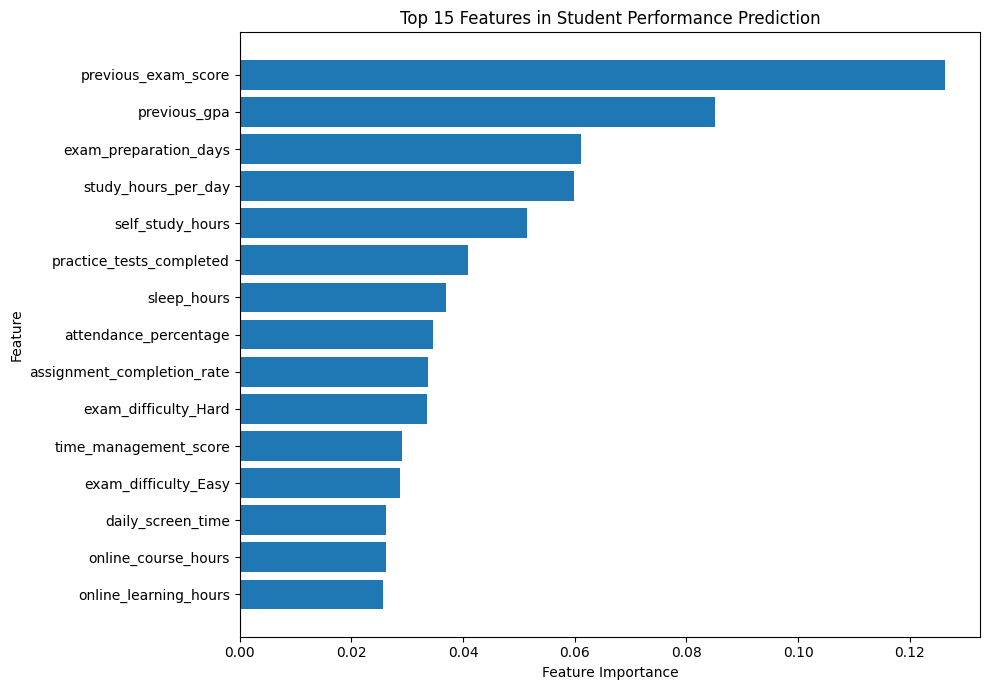

In [50]:

import matplotlib.pyplot as plt

top_features = importance_df.head(15).sort_values(
    'Importance', ascending=True
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_features['Feature'].str.replace(
        'num__', '', regex=False
    ).str.replace('cat__', '', regex=False),
    top_features['Importance']
)

plt.xlabel('Feature Importance')
plt.ylabel('Feature')
plt.title('Top 15 Features in Student Performance Prediction')
plt.tight_layout()
plt.show()


In [51]:

print("Target name:", y_train.name)

print("\nCheck for possible data leakage:")
for col in ['exam_score', 'grade', 'pass_status']:
    print(col, "->", col in X_train.columns)

print("\nAll feature columns:")
print(X_train.columns.tolist())


Target name: pass_status

Check for possible data leakage:
exam_score -> False
grade -> False
pass_status -> False

All feature columns:
['age', 'gender', 'education_level', 'school_type', 'family_income', 'parent_education', 'urban_rural', 'previous_exam_score', 'previous_gpa', 'attendance_percentage', 'assignment_completion_rate', 'class_participation', 'study_hours_per_day', 'self_study_hours', 'private_tuition', 'online_learning_hours', 'study_consistency', 'study_environment', 'study_method', 'revision_frequency', 'practice_tests_completed', 'notes_quality', 'sleep_hours', 'sleep_quality', 'daily_screen_time', 'physical_activity_hours', 'break_frequency', 'stress_level', 'motivation_level', 'internet_access', 'device_availability', 'educational_app_usage', 'online_course_hours', 'exam_difficulty', 'exam_preparation_days', 'questions_attempted', 'time_management_score', 'exam_anxiety_level']


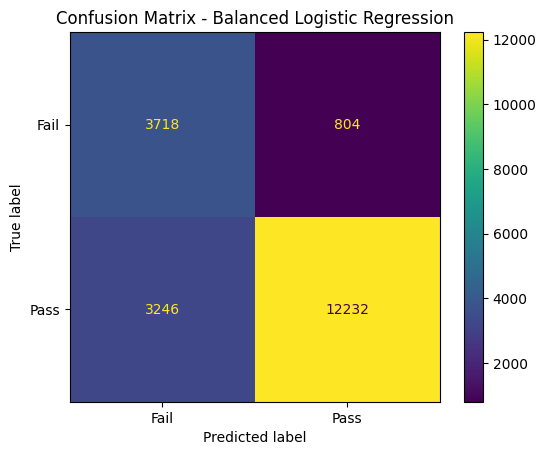

In [52]:

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

y_pred_balanced = model.predict(X_test)

cm = confusion_matrix(
    y_test,
    y_pred_balanced,
    labels=['Fail', 'Pass']
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Fail', 'Pass']
)

disp.plot(values_format='d')
plt.title("Confusion Matrix - Balanced Logistic Regression")
plt.show()


In [53]:

print(df.groupby('pass_status')['exam_score'].agg(
    ['count', 'min', 'max', 'mean', 'median']
))

print("\nPass/Fail counts:")
print(df['pass_status'].value_counts())

print("\nPass status and exam score:")
print(pd.crosstab(
    df['pass_status'],
    pd.cut(df['exam_score'], bins=[0, 50, 60, 70, 80, 90, 100],
           include_lowest=True)
))


             count   min     max       mean  median
pass_status                                        
Fail         22611   0.0   49.99  40.765101   42.74
Pass         77389  50.0  100.00  68.139755   66.56

Pass/Fail counts:
pass_status
Pass    77389
Fail    22611
Name: count, dtype: int64

Pass status and exam score:
exam_score   (-0.001, 50.0]  (50.0, 60.0]  (60.0, 70.0]  (70.0, 80.0]  \
pass_status                                                             
Fail                  22611             0             0             0   
Pass                     17         22520         24086         17901   

exam_score   (80.0, 90.0]  (90.0, 100.0]  
pass_status                               
Fail                    0              0  
Pass                 8796           4069  


In [54]:

expected_status = df['exam_score'].ge(50).map({
    True: 'Pass',
    False: 'Fail'
})

matches = (df['pass_status'] == expected_status)

print("Records matching the 50-point rule:",
      matches.sum(), "out of", len(df))

print("Match percentage:", round(matches.mean() * 100, 2), "%")

print("\nRecords that do not match:")
print(df.loc[~matches, ['exam_score', 'pass_status']].head(10))


Records matching the 50-point rule: 100000 out of 100000
Match percentage: 100.0 %

Records that do not match:
Empty DataFrame
Columns: [exam_score, pass_status]
Index: []


In [55]:

print(df.corr(numeric_only=True)['exam_score'].sort_values(
    ascending=False
))


exam_score                    1.000000
questions_correct             0.975310
previous_exam_score           0.494438
previous_gpa                  0.467763
study_hours_per_day           0.363243
self_study_hours              0.342955
practice_tests_completed      0.316475
assignment_completion_rate    0.221118
exam_preparation_days         0.198577
sleep_hours                   0.170600
attendance_percentage         0.169138
time_management_score         0.106826
daily_screen_time             0.004760
private_tuition               0.003833
questions_attempted           0.003539
internet_access               0.002203
online_course_hours           0.000668
physical_activity_hours      -0.000309
online_learning_hours        -0.002573
age                          -0.003493
exam_anxiety_level           -0.129932
stress_level                 -0.162345
Name: exam_score, dtype: float64


In [56]:

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

# Remove features that may not be available before the exam
X_clean = X.drop(
    columns=['questions_correct', 'questions_attempted'],
    errors='ignore'
)

# Identify the columns from the CLEAN dataset
categorical_cols = X_clean.select_dtypes(
    include=['object', 'category', 'bool']
).columns

numerical_cols = X_clean.select_dtypes(
    include=['number']
).columns

# Prepare the preprocessing steps
numeric_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor_clean = ColumnTransformer([
    ('num', numeric_transformer, numerical_cols),
    ('cat', categorical_transformer, categorical_cols)
])

# Create a fresh model
fast_model = Pipeline([
    ('preprocessor', preprocessor_clean),
    ('classifier', LogisticRegression(
        max_iter=500,
        class_weight='balanced',
        solver='liblinear'
    ))
])

# Split the data
X_train_clean, X_test_clean, y_train_clean, y_test_clean = train_test_split(
    X_clean, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Train and evaluate
fast_model.fit(X_train_clean, y_train_clean)

predictions = fast_model.predict(X_test_clean)

print("Accuracy:", accuracy_score(y_test_clean, predictions))
print(classification_report(y_test_clean, predictions))


Accuracy: 0.7972
              precision    recall  f1-score   support

        Fail       0.53      0.82      0.65      4522
        Pass       0.94      0.79      0.86     15478

    accuracy                           0.80     20000
   macro avg       0.74      0.81      0.75     20000
weighted avg       0.85      0.80      0.81     20000



In [57]:
print("Features used by the model:")
print(list(X_clean.columns))

Features used by the model:
['age', 'gender', 'education_level', 'school_type', 'family_income', 'parent_education', 'urban_rural', 'previous_exam_score', 'previous_gpa', 'attendance_percentage', 'assignment_completion_rate', 'class_participation', 'study_hours_per_day', 'self_study_hours', 'private_tuition', 'online_learning_hours', 'study_consistency', 'study_environment', 'study_method', 'revision_frequency', 'practice_tests_completed', 'notes_quality', 'sleep_hours', 'sleep_quality', 'daily_screen_time', 'physical_activity_hours', 'break_frequency', 'stress_level', 'motivation_level', 'internet_access', 'device_availability', 'educational_app_usage', 'online_course_hours', 'exam_difficulty', 'exam_preparation_days', 'time_management_score', 'exam_anxiety_level']


In [58]:
print("Target distribution:")
print(y.value_counts())

print("\nMissing values in features:")
print(X_clean.isnull().sum().sort_values(ascending=False).head(10))

print("\nDataset preview:")
print(X_clean.head())

Target distribution:
pass_status
Pass    77389
Fail    22611
Name: count, dtype: int64

Missing values in features:
attendance_percentage    9863
time_management_score    9613
notes_quality            8407
previous_gpa             7793
sleep_quality            6994
parent_education         6526
device_availability      2965
family_income               0
gender                      0
age                         0
dtype: int64

Dataset preview:
   age  gender education_level school_type family_income parent_education  \
0   20  Female     High School      Public        Middle              NaN   
1   17    Male     High School      Public        Middle              NaN   
2   18   Other   Undergraduate      Public        Middle           Master   
3   20    Male     High School      Public        Middle      High School   
4   16  Female     High School     Private          High         Bachelor   

  urban_rural  previous_exam_score  previous_gpa  attendance_percentage  ...  \
0       Ru

In [59]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, classification_report

rf_model = Pipeline([
    ('preprocessor', preprocessor_clean),
    ('classifier', RandomForestClassifier(
        n_estimators=100,
        class_weight='balanced',
        random_state=42,
        n_jobs=-1
    ))
])

rf_model.fit(X_train_clean, y_train_clean)

rf_predictions = rf_model.predict(X_test_clean)

print("Random Forest Accuracy:",
      accuracy_score(y_test_clean, rf_predictions))

print("\nClassification Report:")
print(classification_report(y_test_clean, rf_predictions))


Random Forest Accuracy: 0.83625

Classification Report:
              precision    recall  f1-score   support

        Fail       0.77      0.39      0.52      4522
        Pass       0.85      0.97      0.90     15478

    accuracy                           0.84     20000
   macro avg       0.81      0.68      0.71     20000
weighted avg       0.83      0.84      0.82     20000



In [60]:

import pandas as pd

feature_names = rf_model.named_steps[
    'preprocessor'
].get_feature_names_out()

importances = rf_model.named_steps[
    'classifier'
].feature_importances_

importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
})

importance_df = importance_df.sort_values(
    by='Importance',
    ascending=False
)

print(importance_df.head(15).to_string(index=False))



                        Feature  Importance
       num__previous_exam_score    0.126134
              num__previous_gpa    0.086489
       num__study_hours_per_day    0.062186
     num__exam_preparation_days    0.061695
          num__self_study_hours    0.051743
  num__practice_tests_completed    0.040415
               num__sleep_hours    0.037790
     num__attendance_percentage    0.035631
num__assignment_completion_rate    0.033951
      cat__exam_difficulty_Hard    0.033851
     num__time_management_score    0.029496
      cat__exam_difficulty_Easy    0.029003
     num__online_learning_hours    0.026758
       num__online_course_hours    0.026694
         num__daily_screen_time    0.026576


In [61]:

print("Original dataset columns:")
print(df.columns.tolist())

print("\nExam score summary:")
print(df['exam_score'].describe())

print("\nPass/fail check:")
print(
    (df['pass_status'] == (df['exam_score'] >= 50)
     .map({True: 'Pass', False: 'Fail'})).value_counts()
)


Original dataset columns:
['student_id', 'age', 'gender', 'education_level', 'school_type', 'family_income', 'parent_education', 'urban_rural', 'previous_exam_score', 'previous_gpa', 'attendance_percentage', 'assignment_completion_rate', 'class_participation', 'study_hours_per_day', 'self_study_hours', 'private_tuition', 'online_learning_hours', 'study_consistency', 'study_environment', 'study_method', 'revision_frequency', 'practice_tests_completed', 'notes_quality', 'sleep_hours', 'sleep_quality', 'daily_screen_time', 'physical_activity_hours', 'break_frequency', 'stress_level', 'motivation_level', 'internet_access', 'device_availability', 'educational_app_usage', 'online_course_hours', 'exam_difficulty', 'exam_preparation_days', 'questions_attempted', 'questions_correct', 'time_management_score', 'exam_anxiety_level', 'exam_score', 'performance_grade', 'pass_status', 'performance_level']

Exam score summary:
count    100000.000000
mean         61.950072
std          15.863644
min   

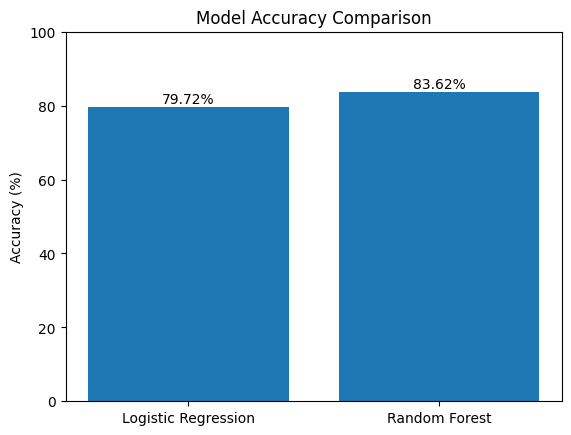

In [62]:
import matplotlib.pyplot as plt

models = ['Logistic Regression', 'Random Forest']
accuracies = [79.72, 83.625]

plt.bar(models, accuracies)
plt.ylabel('Accuracy (%)')
plt.title('Model Accuracy Comparison')
plt.ylim(0, 100)

for i, value in enumerate(accuracies):
    plt.text(i, value + 1, f'{value:.2f}%', ha='center')

plt.show()

In [63]:

from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, classification_report

dt_model = Pipeline([
    ('preprocessor', preprocessor_clean),
    ('classifier', DecisionTreeClassifier(
        class_weight='balanced',
        max_depth=10,
        random_state=42
    ))
])

dt_model.fit(X_train_clean, y_train_clean)

dt_predictions = dt_model.predict(X_test_clean)

print("Decision Tree Accuracy:",
      accuracy_score(y_test_clean, dt_predictions))

print("\nClassification Report:")
print(classification_report(y_test_clean, dt_predictions))


Decision Tree Accuracy: 0.7699

Classification Report:
              precision    recall  f1-score   support

        Fail       0.49      0.78      0.61      4522
        Pass       0.92      0.77      0.84     15478

    accuracy                           0.77     20000
   macro avg       0.71      0.77      0.72     20000
weighted avg       0.83      0.77      0.79     20000

